# 03 · Análise morfológica

Visualizações **morfológicas** (quais classes e formas gramaticais dominam), lidas do CSV do notebook 01. **Nenhum modelo é executado aqui.**

**Sem filtro de stopwords:** palavras funcionais carregam morfologia (determinantes têm gênero e número; pronomes, pessoa). **A unidade é a ocorrência do token, não o lema**: traços como número, tempo e modo pertencem à forma flexionada ("águas" é plural), e lematizar os apagaria.

| Parâmetro | Significado |
|---|---|
| `MODELO`, `CONTEXTO` | escolhem o arquivo `dados/analise/tokens_{contexto}_{modelo}.csv` |
| `TOP` | tamanho do ranking de traços agregados |
| `MIN_OCORRENCIAS` | combinações classe × traço × valor com menos ocorrências são descartadas da tabela |

Saídas em `saida/morfologica/{modelo}_{contexto}/`. Se o modelo não fornece traços, o notebook avisa e gera só a parte de classes (UPOS).

## 0. Parâmetros

In [9]:
# ===================== PARÂMETROS (edite aqui) =====================
MODELO = "spacy"            # spacy | stanza | udpipe2 | trankit | bertimbau_ft
CONTEXTO = "poema"          # token | verso | poema
TOP = 50                    # tamanho do ranking de traços agregados
MIN_OCORRENCIAS = 0        # mínimo de ocorrências de uma combinação classe × traço × valor
# ===================================================================

In [10]:
import sys
from pathlib import Path

# raiz do projeto: a pasta que contém src/ (funciona rodando de projeto/ ou de projeto/notebooks/)
RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import pandas as pd
from IPython.display import display

from src import carga, graficos, metricas

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

carga.validar_parametros(MODELO, CONTEXTO)
tokens = carga.carregar_tokens(MODELO, CONTEXTO)         # para com mensagem se o notebook 01 não foi rodado
PASTA = carga.pasta_saida("morfologica", MODELO, CONTEXTO)

if not carga.tem_upos(tokens):
    raise SystemExit(f"O modelo '{MODELO}' não forneceu classe gramatical: nada a analisar neste notebook.")
tem_tracos = carga.tem_morph(tokens)
if not tem_tracos:
    print(f"AVISO: o modelo '{MODELO}' não forneceu traços morfológicos: só a parte de classes (UPOS) será gerada.")
print(f"{len(tokens)} tokens | modelo={MODELO} contexto={CONTEXTO}")
print("Saídas em:", PASTA)

9683 tokens | modelo=spacy contexto=poema
Saídas em: C:\Users\Usuário\Desktop\Portinari_analise\saida\morfologica\spacy_poema


## 1. Classes gramaticais (UPOS)

Frequência (nº de palavras) de cada classe, com a proporção ao lado das barras. PUNCT e SYM ficam fora.

,upos,n,prop
0,NOUN,2546,0.263
1,VERB,1696,0.175
2,ADP,1396,0.144
3,DET,1264,0.131
4,ADV,625,0.065
5,ADJ,562,0.058
6,PRON,484,0.050
7,CCONJ,442,0.046
8,AUX,241,0.025
9,PROPN,191,0.020


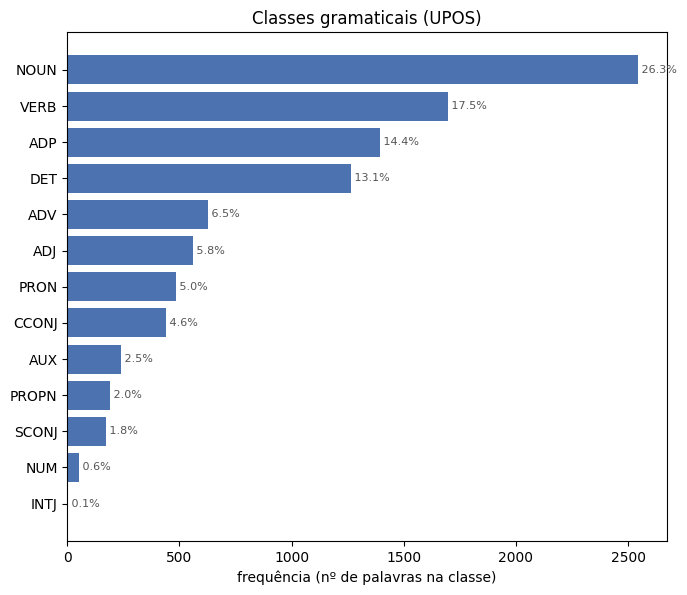

In [11]:
tab_upos = metricas.distribuicao_upos(tokens)
tab_upos.to_csv(PASTA / "upos.csv", index=False)
display(tab_upos)
graficos.barras_upos(tab_upos, metricas.NOMES_CLASSES, PASTA / "upos.png")

## 2. Traços morfológicos por classe

Para cada classe, a proporção de cada valor dos traços de interesse (ex.: `Tense` entre os verbos, `Gender` entre os substantivos). A proporção é calculada sobre todas as ocorrências da classe com aquele traço; combinações com menos de `MIN_OCORRENCIAS` ocorrências ficam fora da tabela (por isso as proporções da tabela podem somar menos de 1).

Atenção: preposições, advérbios e conjunções normalmente não têm traço algum, o que é esperado no esquema UD.

In [12]:
if not tem_tracos:
    print("AVISO: sem traços morfológicos: seção pulada.")
else:
    m = metricas.tracos_explodidos(tokens)
    tab_ctv = metricas.tabela_classe_traco_valor(m, MIN_OCORRENCIAS)
    tab_ctv.to_csv(PASTA / "classe_traco_valor.csv", index=False)
    n_sem = int(((tokens["morph"] == "") & ~tokens["upos"].isin(metricas.CLASSES_FORA_DA_MORFOLOGIA)).sum())
    print(f"{len(m)} pares ocorrência × traço; {n_sem} palavras sem nenhum traço")
    display(tab_ctv)

24069 pares ocorrência × traço; 1789 palavras sem nenhum traço


,upos,feature,valor,n,prop_na_classe
0,ADJ,Gender,Masc,313,0.557
1,ADJ,Gender,Fem,249,0.443
2,ADJ,NumType,Ord,16,1.000
3,ADJ,Number,Sing,330,0.587
4,ADJ,Number,Plur,232,0.413
...,...,...,...,...,...
92,VERB,VerbForm,Fin,1084,0.639
93,VERB,VerbForm,Part,238,0.140
94,VERB,VerbForm,Inf,202,0.119
95,VERB,VerbForm,Ger,172,0.101


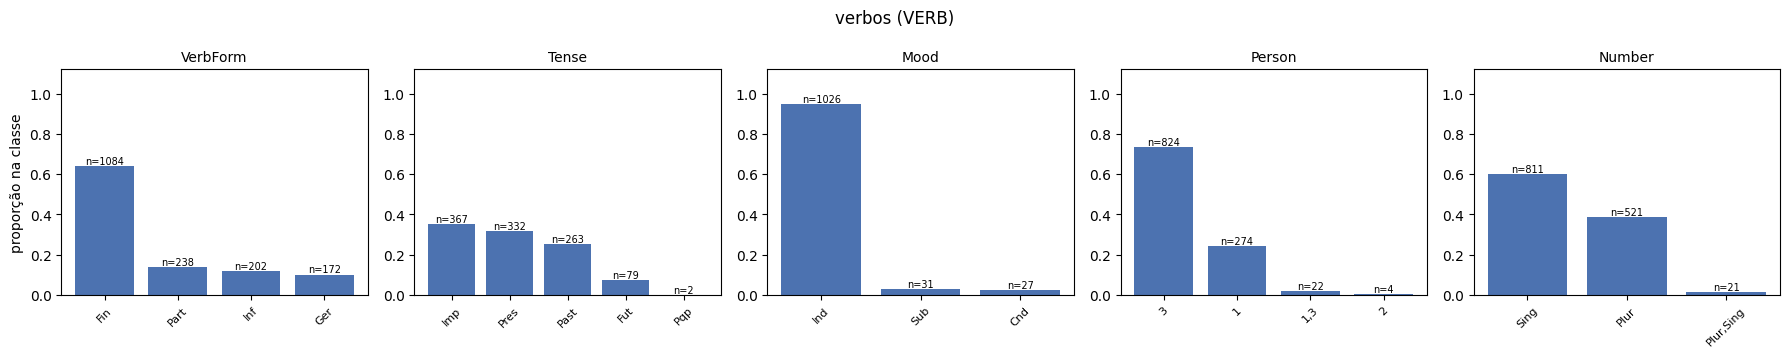

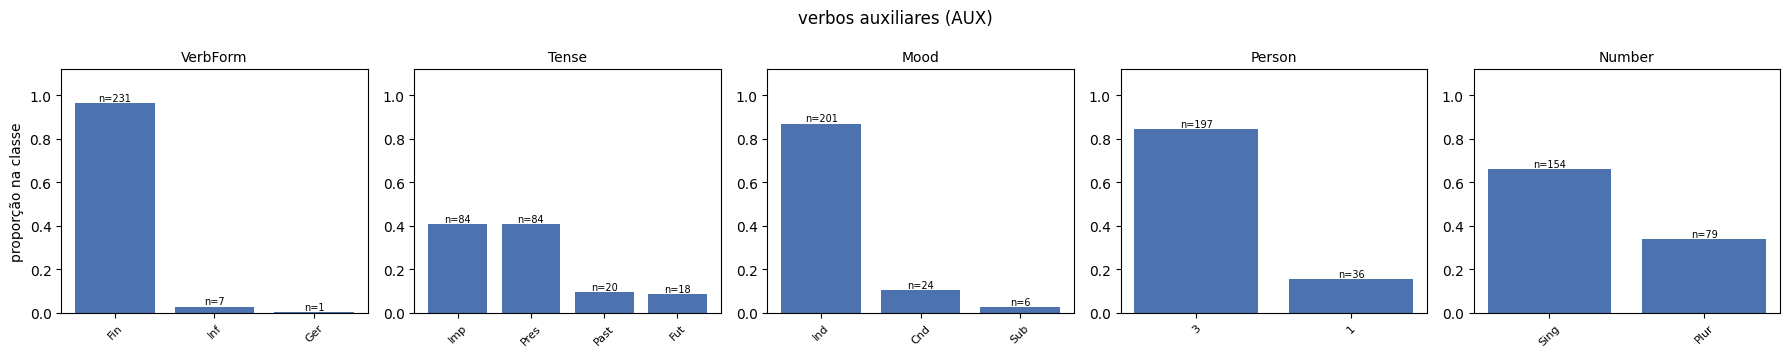

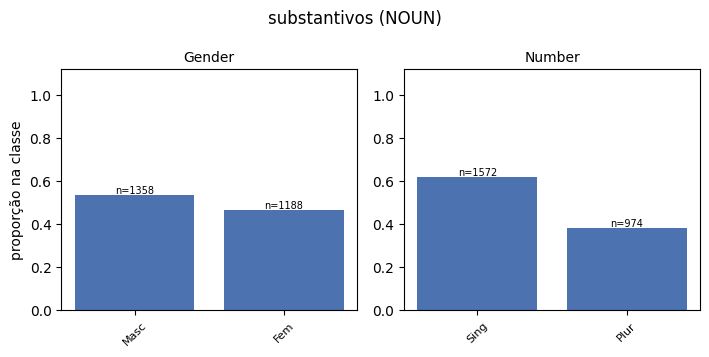

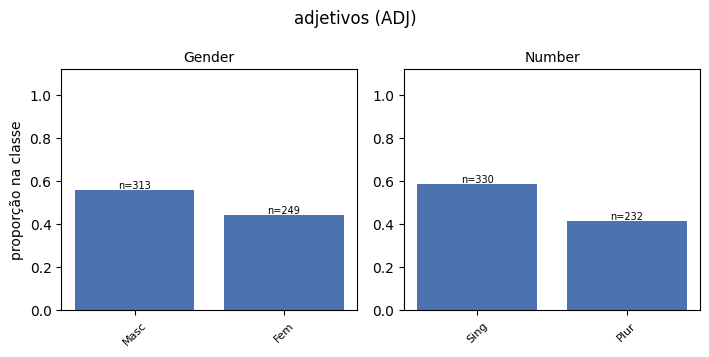

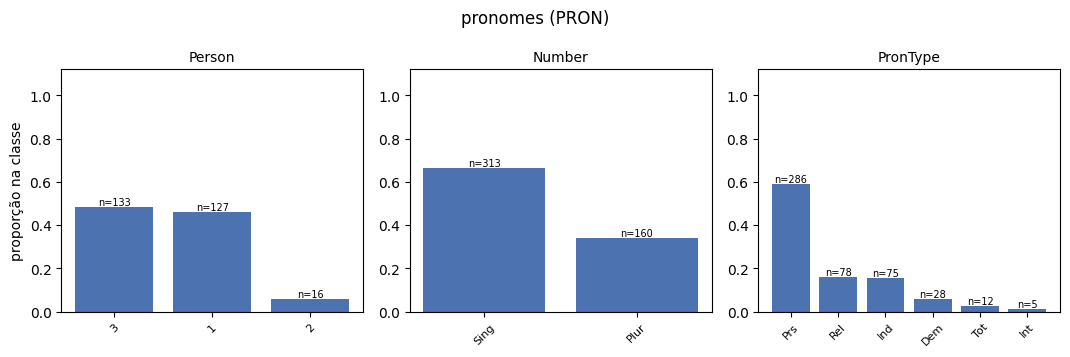

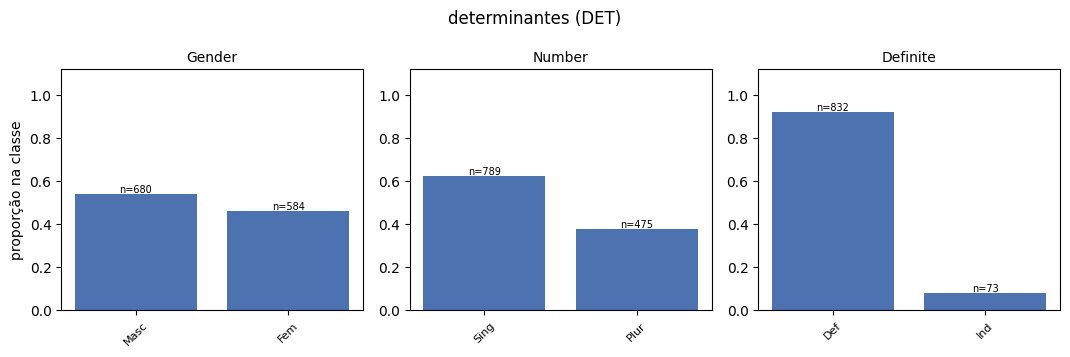

In [13]:
if tem_tracos:
    for classe, tracos_foco in metricas.FOCOS_MORF:
        gerou = graficos.barras_traco_por_classe(
            tab_ctv, classe, tracos_foco, metricas.NOMES_CLASSES.get(classe, classe), PASTA / f"tracos_{classe}.png")
        if not gerou:
            print(f"({classe}: sem combinações com pelo menos {MIN_OCORRENCIAS} ocorrências)")

## 3. Verbos: forma verbal, tempo e modo (VERB + AUX)

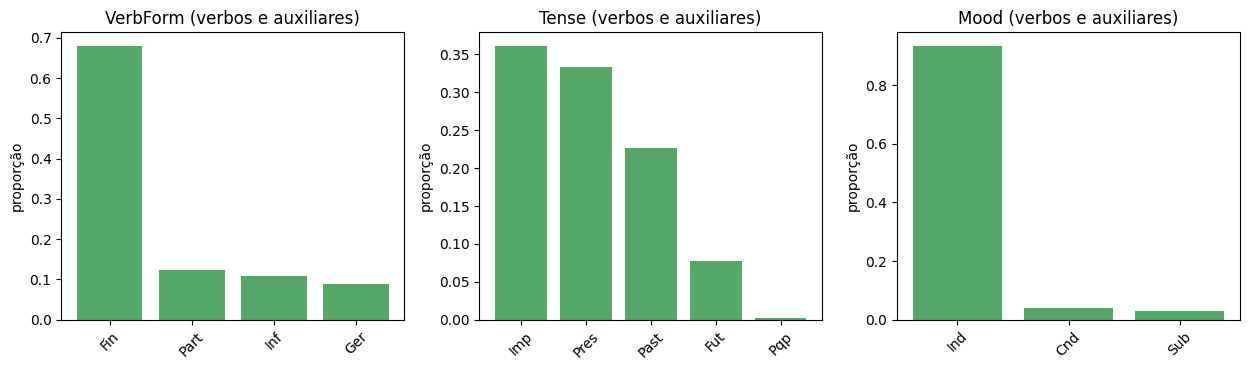

In [14]:
if tem_tracos and not graficos.figura_verbos(m, PASTA / "verbos.png"):
    print("(sem traços verbais)")

## 4. Traços agregados

**Atenção:** a contagem mistura classes (um `Number=Sing` de substantivo e um de verbo contam igual). Use a seção 2 para interpretar.

,traco,n,prop_palavras
0,Number=Sing,4593,0.475
1,Gender=Masc,3372,0.348
2,Number=Plur,2714,0.280
3,Gender=Fem,2540,0.262
4,PronType=Art,1589,0.164
5,Definite=Def,1494,0.154
6,VerbForm=Fin,1315,0.136
7,Mood=Ind,1227,0.127
8,Person=3,1154,0.119
9,PronType=Prs,581,0.060


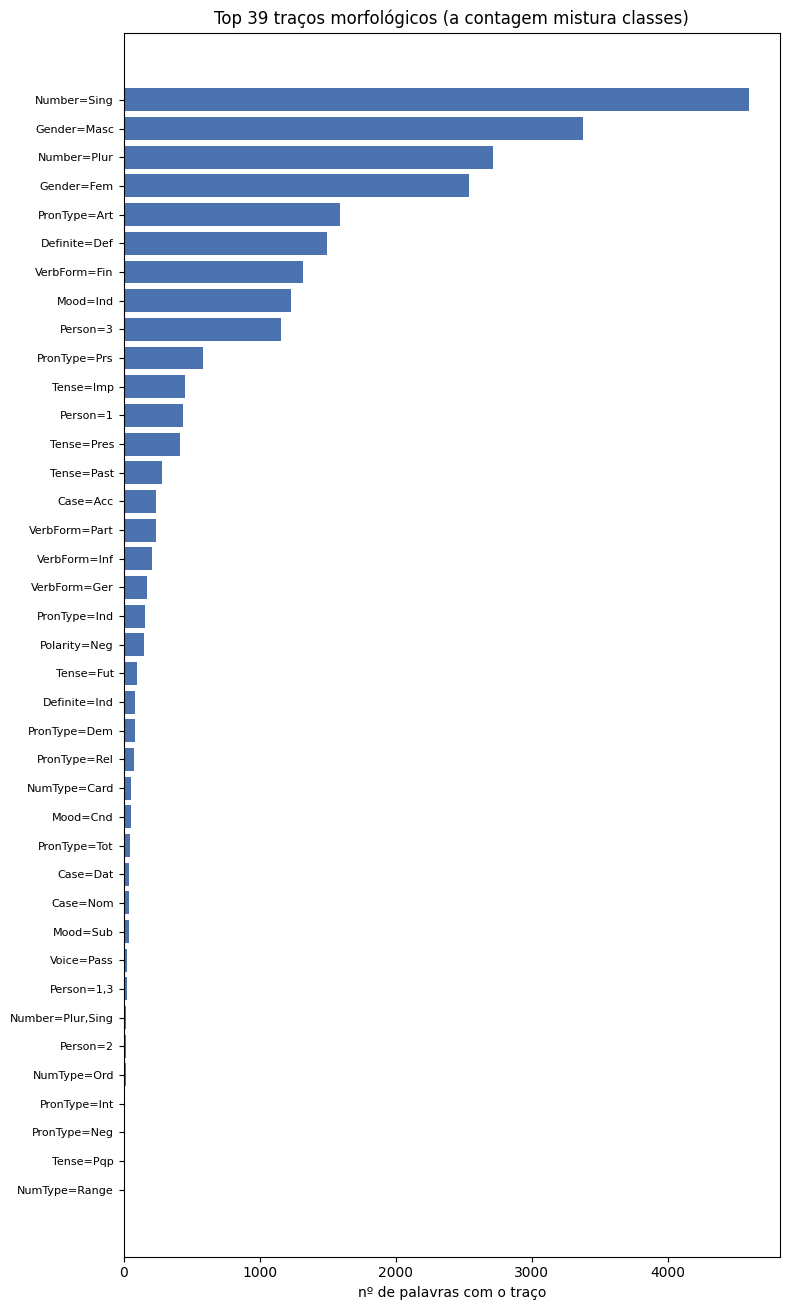

In [15]:
if tem_tracos:
    n_palavras = int((~tokens["upos"].isin(metricas.CLASSES_FORA_DA_MORFOLOGIA)).sum())
    tab_tracos = metricas.top_tracos(m, n_palavras)
    tab_tracos.to_csv(PASTA / "top_tracos.csv", index=False)
    display(tab_tracos.head(TOP))
    graficos.barras_tracos(tab_tracos, TOP, PASTA / "top_tracos.png")

## Observações

- **As etiquetas dependem do modelo e do contexto**; compare execuções com outro `MODELO` ou `CONTEXTO` (fase seguinte: notebook de comparação).
- **Poucos dados**: proporções de combinações com poucas ocorrências são instáveis.